In [ ]:
from google.colab import drive
try:
    drive.mount('/content/drive')   
except Exception as e:
    print('Not running in Colab or mount failed:', e)

Mounted at /content/drive


In [1]:
!pip install numpy pandas pyarrow scikit-learn matplotlib seaborn pytest kagglehub

In [3]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("sobhanmoosavi/us-accidents")

print("Path to dataset files:", path)


100%|██████████| 653M/653M [00:16<00:00, 40.8MB/s] 

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/sobhanmoosavi/us-accidents/versions/13


In [4]:
from pathlib import Path
import pandas as pd


dataset_dir = Path(path)

csv_files = list(dataset_dir.rglob("*.csv"))


csv_path = csv_files[0]
df_sample = pd.read_csv(csv_path, nrows=10_000)

print(df_sample.shape)
df_sample.head()
df_sample.info()
df_sample.describe()

(10000, 46)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 46 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   ID                     10000 non-null  object 
 1   Source                 10000 non-null  object 
 2   Severity               10000 non-null  int64  
 3   Start_Time             10000 non-null  object 
 4   End_Time               10000 non-null  object 
 5   Start_Lat              10000 non-null  float64
 6   Start_Lng              10000 non-null  float64
 7   End_Lat                0 non-null      float64
 8   End_Lng                0 non-null      float64
 9   Distance(mi)           10000 non-null  float64
 10  Description            10000 non-null  object 
 11  Street                 10000 non-null  object 
 12  City                   10000 non-null  object 
 13  County                 10000 non-null  object 
 14  State                  10000 non-null  obje

,Severity,Start_Lat,Start_Lng,End_Lat,End_Lng,Distance(mi),Temperature(F),Wind_Chill(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Speed(mph),Precipitation(in)
count,10000.00000,10000.000000,10000.000000,0.0,0.0,10000.000000,9915.000000,1426.000000,9876.000000,9965.000000,9904.000000,8226.000000,1123.000000
mean,2.39470,38.128680,-119.041084,NaN,NaN,0.021386,59.643732,33.126157,64.083131,30.012505,8.914297,8.860528,0.027720
std,0.49126,0.749559,9.963780,NaN,NaN,0.397797,17.369289,10.297458,24.475341,0.316665,2.570054,4.592276,0.046018
min,1.00000,36.352592,-123.810753,NaN,NaN,0.000000,3.900000,-8.400000,8.000000,3.010000,0.200000,1.200000,0.000000
25%,2.00000,37.643864,-122.159031,NaN,NaN,0.000000,48.200000,27.500000,46.000000,29.900000,10.000000,5.800000,0.000000
50%,2.00000,37.959778,-121.875954,NaN,NaN,0.010000,57.000000,36.400000,67.000000,30.010000,10.000000,8.100000,0.010000
75%,3.00000,38.574538,-121.349976,NaN,NaN,0.010000,71.100000,40.800000,86.000000,30.120000,10.000000,11.500000,0.040000
max,4.00000,41.428753,-81.550728,NaN,NaN,24.040000,106.000000,66.000000,100.000000,30.620000,80.000000,33.400000,0.490000


Removed constant columns:
['Turning_Loop']

Correlations with Severity:
Traffic_Signal    -0.189
Crossing          -0.172
Junction           0.168
Start_Lng         -0.146
Stop              -0.108
Start_Lat         -0.085
Amenity           -0.079
Wind_Speed(mph)    0.069
Visibility(mi)     0.062
Station           -0.057
is_weekend         0.055
hour_cos           0.053
month_cos         -0.050
Pressure(in)      -0.048
Temperature(F)     0.043
Give_Way          -0.043
Humidity(%)       -0.041
Railway           -0.041
No_Exit            0.035
Distance(mi)       0.032
is_day            -0.020
Bump               0.013
Roundabout        -0.011
month_sin         -0.010
hour_sin          -0.008
Traffic_Calming    0.002
Name: Severity, dtype: float64


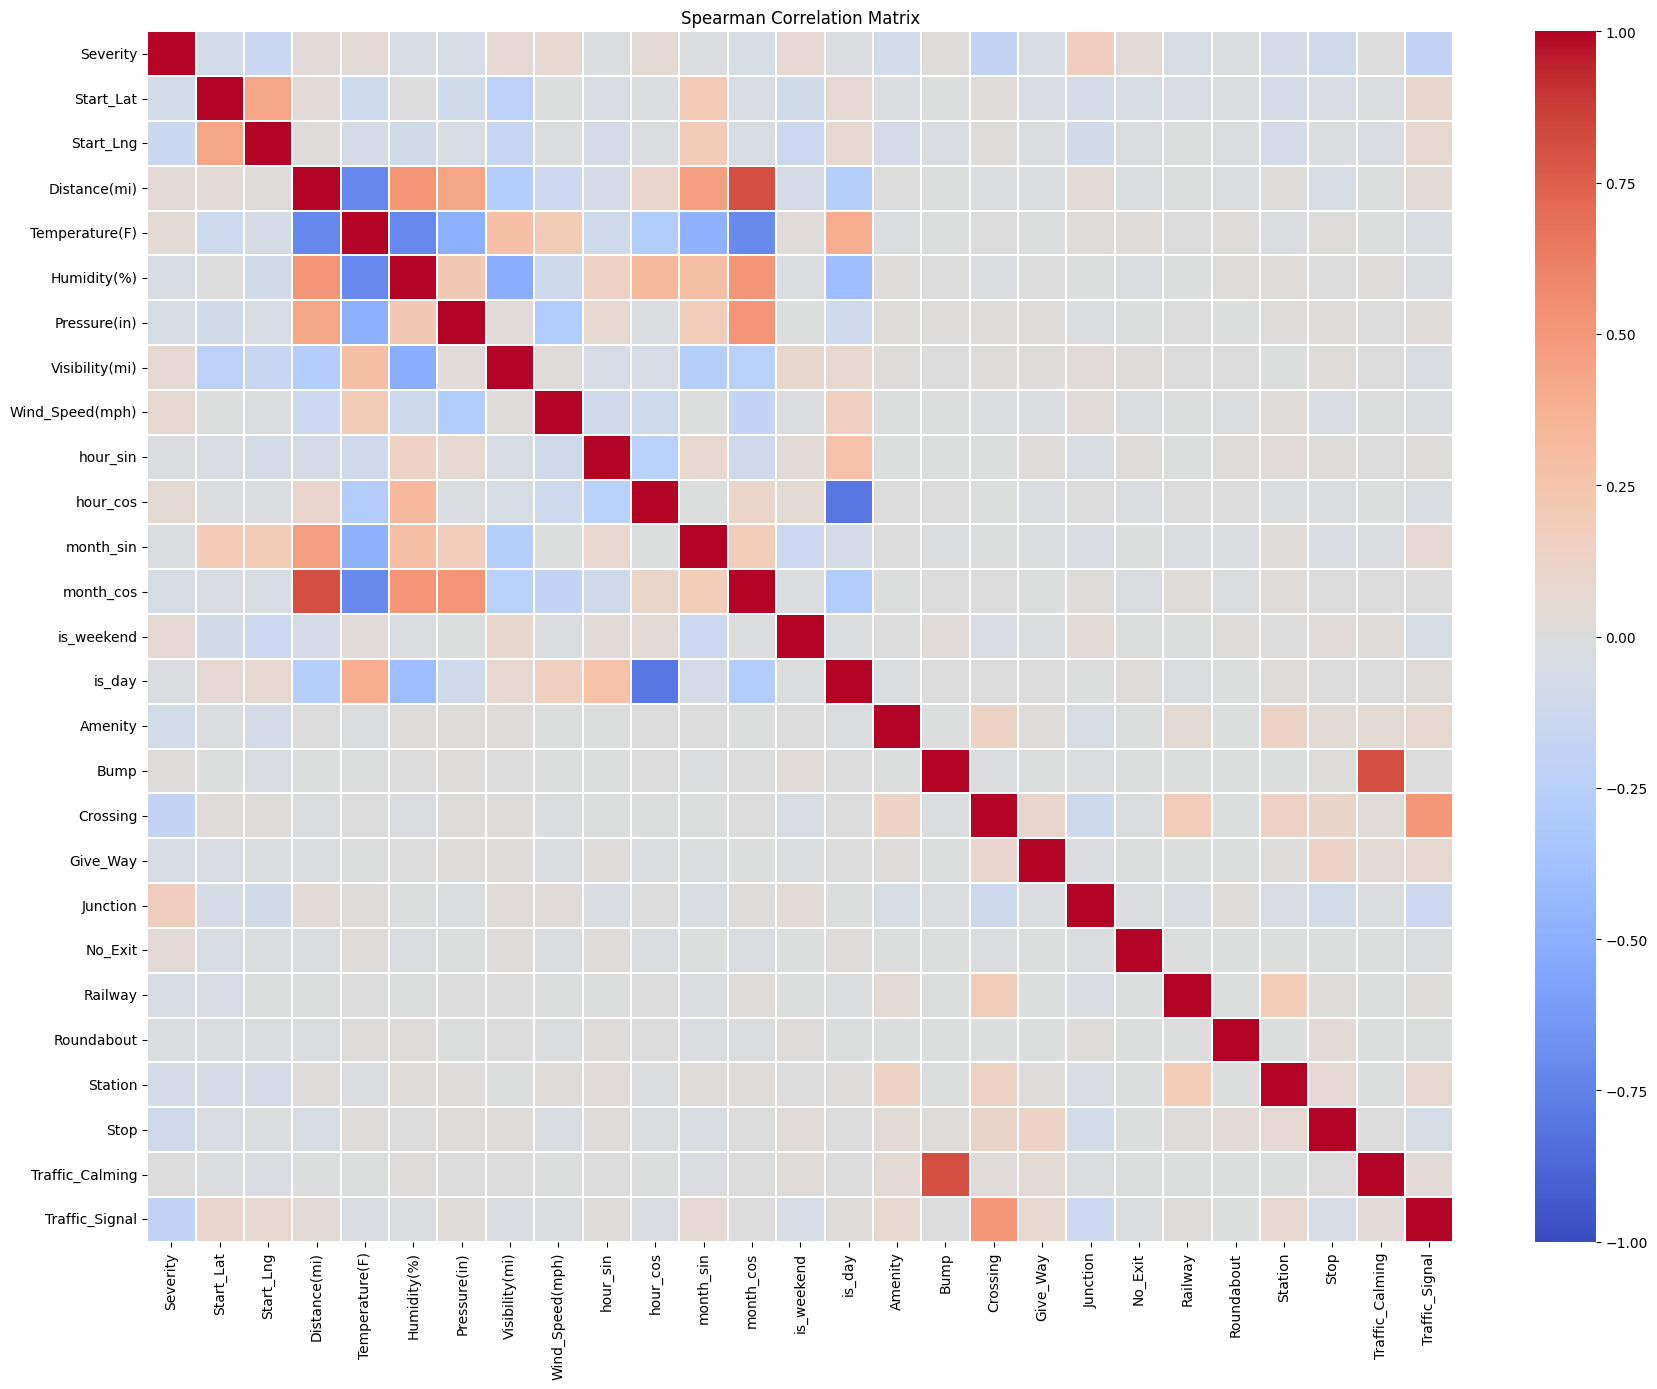

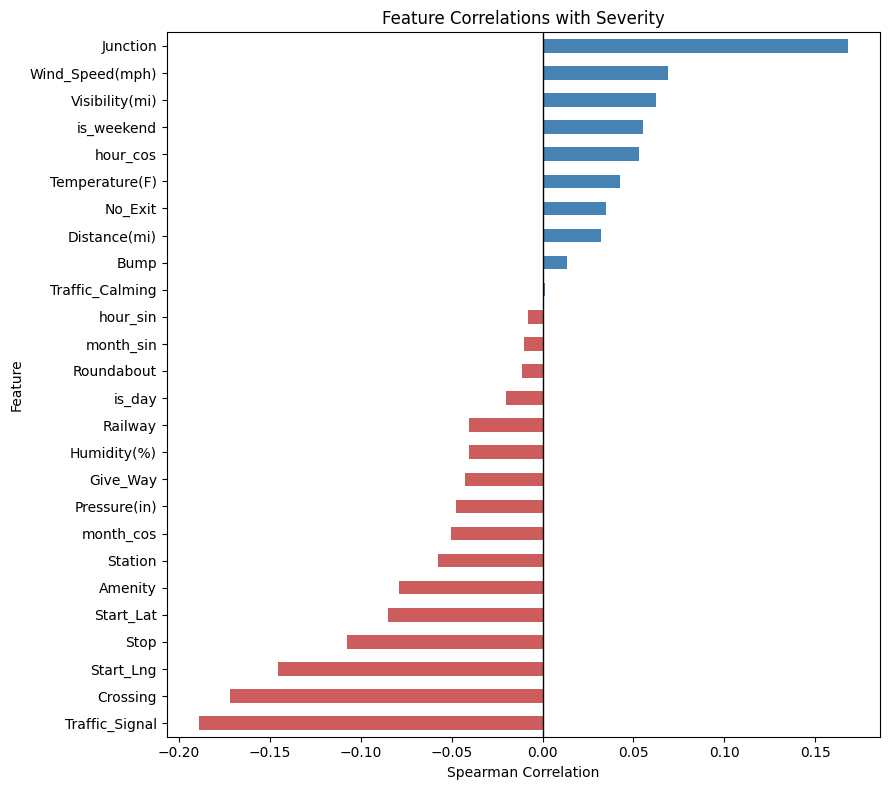

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Work on a copy
corr_df = df_sample.copy()

# --------------------------------------------------
# 1. Parse Start_Time and engineer useful time fields
# --------------------------------------------------
corr_df["Start_Time"] = pd.to_datetime(
    corr_df["Start_Time"],
    errors="coerce"
)

corr_df["hour"] = corr_df["Start_Time"].dt.hour
corr_df["month"] = corr_df["Start_Time"].dt.month
corr_df["day_of_week"] = corr_df["Start_Time"].dt.dayofweek

corr_df["is_weekend"] = (
    corr_df["day_of_week"].isin([5, 6]).astype("int8")
)

# Cyclical time features
corr_df["hour_sin"] = np.sin(
    2 * np.pi * corr_df["hour"] / 24
)
corr_df["hour_cos"] = np.cos(
    2 * np.pi * corr_df["hour"] / 24
)

corr_df["month_sin"] = np.sin(
    2 * np.pi * corr_df["month"] / 12
)
corr_df["month_cos"] = np.cos(
    2 * np.pi * corr_df["month"] / 12
)

# --------------------------------------------------
# 2. Convert day/night to binary
# --------------------------------------------------
corr_df["is_day"] = corr_df["Sunrise_Sunset"].map({
    "Day": 1,
    "Night": 0
})

# --------------------------------------------------
# 3. Convert boolean road features to 0/1
# --------------------------------------------------
boolean_columns = [
    "Amenity",
    "Bump",
    "Crossing",
    "Give_Way",
    "Junction",
    "No_Exit",
    "Railway",
    "Roundabout",
    "Station",
    "Stop",
    "Traffic_Calming",
    "Traffic_Signal",
    "Turning_Loop",
]

for column in boolean_columns:
    corr_df[column] = corr_df[column].astype("int8")

# --------------------------------------------------
# 4. Select correlation columns
# --------------------------------------------------
correlation_columns = [
    "Severity",
    "Start_Lat",
    "Start_Lng",
    "Distance(mi)",
    "Temperature(F)",
    "Humidity(%)",
    "Pressure(in)",
    "Visibility(mi)",
    "Wind_Speed(mph)",
    "hour_sin",
    "hour_cos",
    "month_sin",
    "month_cos",
    "is_weekend",
    "is_day",
] + boolean_columns

# Keep only columns that exist
correlation_columns = [
    column
    for column in correlation_columns
    if column in corr_df.columns
]

analysis_df = corr_df[correlation_columns].copy()

# --------------------------------------------------
# 5. Remove columns with no variation
# --------------------------------------------------
constant_columns = [
    column
    for column in analysis_df.columns
    if analysis_df[column].nunique(dropna=True) <= 1
]

if constant_columns:
    print("Removed constant columns:")
    print(constant_columns)

analysis_df = analysis_df.drop(columns=constant_columns)

# --------------------------------------------------
# 6. Calculate Spearman correlations
# --------------------------------------------------
correlation_matrix = analysis_df.corr(
    method="spearman",
    min_periods=100
)

# Display correlations with Severity
severity_correlations = (
    correlation_matrix["Severity"]
    .drop("Severity")
    .sort_values(key=lambda values: values.abs(), ascending=False)
)

print("\nCorrelations with Severity:")
print(severity_correlations.round(3))

# --------------------------------------------------
# 7. Plot the full correlation matrix
# --------------------------------------------------
plt.figure(figsize=(18, 14))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    annot=False,
    square=False,
    linewidths=0.25,
)

plt.title("Spearman Correlation Matrix")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 8. Plot correlations with Severity only
# --------------------------------------------------
plt.figure(figsize=(9, 8))

severity_correlations.sort_values().plot(
    kind="barh",
    color=[
        "steelblue" if value >= 0 else "indianred"
        for value in severity_correlations.sort_values()
    ],
)

plt.axvline(0, color="black", linewidth=1)
plt.xlabel("Spearman Correlation")
plt.ylabel("Feature")
plt.title("Feature Correlations with Severity")
plt.tight_layout()
plt.show()



In [ ]:
df_sample["visibility_group"] = pd.cut(
    df_sample["Visibility(mi)"],
    bins=[0, 1, 3, 5, 10, float("inf")],
    labels=["<1", "1-3", "3-5", "5-10", "10+"]
)

pd.crosstab(
    df_sample["visibility_group"],
    df_sample["Severity"],
    normalize="index"
)